# Dự đoán hành vi mua hàng và marketing chính xác (Precision Marketing)

Tái hiện bài báo: **Lin, J. (2025). "Application of machine learning in predicting consumer behavior and precision marketing."** PLOS One 20(5): e0321854. https://doi.org/10.1371/journal.pone.0321854

**Bài toán:** Phân loại nhị phân — dự đoán biến `Revenue` (khách hàng có hoàn tất mua hàng trong một session hay không) trên bộ dữ liệu **Online Shoppers Purchasing Intention Dataset (UCI, 2016)**, cùng bộ dữ liệu bài báo sử dụng (link trong mục Data availability statement của bài báo): https://archive.ics.uci.edu/ml/datasets/Online+Shoppers+Purchasing+Intention+Dataset

**4 model so sánh (đúng như bài báo):** SVM (kernel RBF), XGBoost, CatBoost, BPANN (mạng nơ-ron lan truyền ngược — ở đây viết bằng PyTorch).

**Đánh giá:** bài báo chia train/test 80/20 và lặp lại với 50 random seed khác nhau ("50 random numbers... cyclic algorithm"), báo cáo Precision, Recall, ROC AUC trung bình. Notebook này làm theo đúng giao thức đó (repeated random holdout), mặc định `n_repeats=10` để chạy nhanh trên máy cá nhân — có thể tăng lên 50 để khớp chính xác bài báo (cell cấu hình bên dưới).

**Lưu ý khác biệt quan trọng:** để tránh rò rỉ dữ liệu (data leakage), `IsolationForest` (loại outlier), `SMOTE` (cân bằng lớp) và `StandardScaler` được fit **chỉ trên tập train của từng lần lặp**, rồi áp dụng lên tập test — bài báo không nêu rõ việc này được làm trước hay sau khi chia tập, nên ở đây ta chọn cách an toàn hơn về leakage. Bước chọn đặc trưng (lọc phương sai/skewness, mutual information, tương quan Pearson) được tính một lần trên toàn bộ dữ liệu vì đây là bước xác định *tập đặc trưng cố định* dùng chung cho mọi lần lặp, giống cách trình bày trong bài báo.

## 1. Import thư viện

In [1]:
#Core libraries
import os
import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

#Sklearn utilities
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.ensemble import IsolationForest
from sklearn.svm import SVC
from sklearn.feature_selection import mutual_info_classif
from sklearn.metrics import precision_score, recall_score, roc_auc_score, accuracy_score, roc_curve, confusion_matrix

#Gradient boosting models
from xgboost import XGBClassifier
from catboost import CatBoostClassifier

#Imbalanced-data handling
from imblearn.over_sampling import SMOTE

#PyTorch for BPANN
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader


## 2. Thiết lập seed, device và cấu hình

In [2]:
#Fix random seed for reproducibility
seed = 42
np.random.seed(seed)
torch.manual_seed(seed)

#Auto-detect GPU
devices = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", devices)

#Evaluation protocol config (paper uses n_repeats=50, test_size=0.20)
n_repeats = 10
test_size = 0.20
print(f"n_repeats={n_repeats} (paper: 50, giam de chay nhanh), test_size={test_size}")


Device: cuda
n_repeats=10 (paper: 50, giam de chay nhanh), test_size=0.2


## 3. Tải dữ liệu

In [3]:
#Load the cached UCI Online Shoppers dataset
data_dir = "data_ecommerce"
csv_path = os.path.join(data_dir, "online_shoppers_intention.csv")

if not os.path.exists(csv_path):
    os.makedirs(data_dir, exist_ok=True)
    url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00468/online_shoppers_intention.csv"
    df_raw = pd.read_csv(url)
    df_raw.to_csv(csv_path, index=False)
    print("Downloaded and cached to", csv_path)
else:
    df_raw = pd.read_csv(csv_path)
    print("Loaded from cache:", csv_path)

print(df_raw.shape)
df_raw.head()


Loaded from cache: data_ecommerce\online_shoppers_intention.csv
(12330, 18)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


In [4]:
#Explore basic info
print(df_raw.dtypes)
print("Missing values:", df_raw.isna().sum().sum())
print(df_raw["Revenue"].value_counts())


Administrative               int64
Administrative_Duration    float64
Informational                int64
Informational_Duration     float64
ProductRelated               int64
ProductRelated_Duration    float64
BounceRates                float64
ExitRates                  float64
PageValues                 float64
SpecialDay                 float64
Month                       object
OperatingSystems             int64
Browser                      int64
Region                       int64
TrafficType                  int64
VisitorType                 object
Weekend                       bool
Revenue                       bool
dtype: object
Missing values: 0
Revenue
False    10422
True      1908
Name: count, dtype: int64


## 4. Biểu đồ phân bố lớp

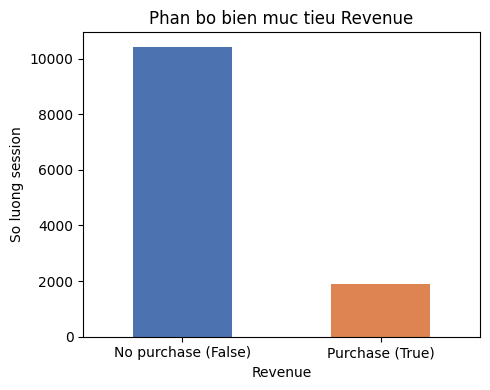

In [5]:
#Plot the class distribution of the target variable
fig, ax = plt.subplots(figsize=(5, 4))
df_raw["Revenue"].value_counts().plot(kind="bar", color=["#4C72B0", "#DD8452"], ax=ax)
ax.set_xticklabels(["No purchase (False)", "Purchase (True)"], rotation=0)
ax.set_ylabel("So luong session")
ax.set_title("Phan bo bien muc tieu Revenue")
plt.tight_layout()
os.makedirs("outputs", exist_ok=True)
plt.savefig("outputs/class_distribution.png", dpi=150)
plt.show()


## 5. Tiền xử lý và chọn đặc trưng

Theo mục 2.3 của bài báo, quy trình gồm 3 bước: lọc theo skewness, lọc theo mutual information, lọc theo tương quan Pearson. Tuy nhiên áp dụng đúng ngưỡng bài báo nêu (skewness > 1 bị loại, MI < 0.05 bị loại) trên bộ dữ liệu UCI này sẽ **loại bỏ toàn bộ đặc trưng**, kể cả `PageValues` — đặc trưng mà chính bài báo xác định là quan trọng nhất (mục 3.5) — vì `PageValues` có skewness = 6.38 (bị lọc theo bước 1) và các đặc trưng mạnh thứ nhì (`ExitRates`, MI = 0.039) không đạt ngưỡng MI = 0.05 (bị lọc theo bước 2). Lý do: các biến đếm/thời lượng trong dữ liệu session web vốn luôn lệch phân phối mạnh, đây là đặc tính tự nhiên của dữ liệu, không phải dấu hiệu dư thừa.

Vì vậy notebook này **điều chỉnh ngưỡng cho phù hợp với dữ liệu thực tế** (ghi rõ là khác biệt so với bài báo):
- Mã hóa `Month`, `VisitorType`, `Weekend` bằng LabelEncoder.
- Bước lọc skewness chỉ dùng để quan sát (không loại đặc trưng).
- Hạ ngưỡng mutual information xuống 0.005 (vẫn loại các đặc trưng gần như không mang thông tin) thay vì 0.05.
- Bỏ một trong hai biến có tương quan Pearson tuyệt đối > 0.7 (giữ biến tương quan mạnh hơn với `Revenue`) — bước này giữ nguyên như bài báo.

In [6]:
#Encode categorical columns with LabelEncoder
df = df_raw.copy()
label_encoders = {}
for col in ["Month", "VisitorType", "Weekend"]:
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col])
    label_encoders[col] = le

#Target as int (0/1)
df["Revenue"] = df["Revenue"].astype(int)

feature_cols = [c for c in df.columns if c != "Revenue"]
X_full = df[feature_cols].copy()
y_full = df["Revenue"].copy()
print(X_full.shape, y_full.shape)


(12330, 17)

 (12330,)


In [7]:
#Skewness check (diagnostic only, see note below)
skewness = X_full.skew().abs()
print(skewness.sort_values(ascending=False))

#NOTE: the paper's literal rule "drop skewness > 1" removes 15/17 columns here,
#including PageValues (skew=6.38) which the paper itself calls the most important
#feature (section 3.5). Right-skewed counts/durations are inherent to this dataset,
#not a sign of redundancy, so we keep this step as a diagnostic plot only and do not
#use it to eliminate features (deviation from the paper, documented here and in the .md files).
high_skew_cols = []


Informational_Duration     7.579185
ProductRelated_Duration    7.263228
PageValues                 6.382964
Administrative_Duration    5.615719
ProductRelated             4.341516
Informational              4.036464
SpecialDay                 3.302667
Browser                    3.242350
BounceRates                2.947855
ExitRates                  2.148789
OperatingSystems           2.066285
VisitorType                2.065135
TrafficType                1.962987
Administrative             1.960357
Weekend                    1.265962
Region                     0.983549
Month                      0.832535
dtype: float64


In [8]:
#Mutual information filter: keep features with MI(feature, Revenue) >= threshold
mi_scores = mutual_info_classif(X_full, y_full, random_state=seed)
mi_series = pd.Series(mi_scores, index=feature_cols).sort_values(ascending=False)
print(mi_series)

#NOTE: the paper's literal threshold (0.05) keeps only PageValues and drops ExitRates
#(MI=0.039) which is the second-most informative feature by far. We use a lower
#threshold (0.005) that still removes the near-zero-information features (Region,
#Weekend, VisitorType) while keeping the features that actually carry signal
#(deviation from the paper, documented here and in the .md files).
mi_threshold = 0.005
low_mi_cols = mi_series[mi_series < mi_threshold].index.tolist()
print(f"Cot bi loai do mutual information < {mi_threshold}:", low_mi_cols)


PageValues                 0.163803
ExitRates                  0.039363
ProductRelated_Duration    0.032343
BounceRates                0.023766
ProductRelated             0.022734
Month                      0.018962
Administrative             0.015711
TrafficType                0.015611
Administrative_Duration    0.014339
Browser                    0.009111
SpecialDay                 0.007427
Informational_Duration     0.006290
OperatingSystems           0.005533
Informational              0.004190
VisitorType                0.003457
Weekend                    0.002040
Region                     0.001382
dtype: float64
Cot bi loai do mutual information < 0.005: ['Informational', 'VisitorType', 'Weekend', 'Region']


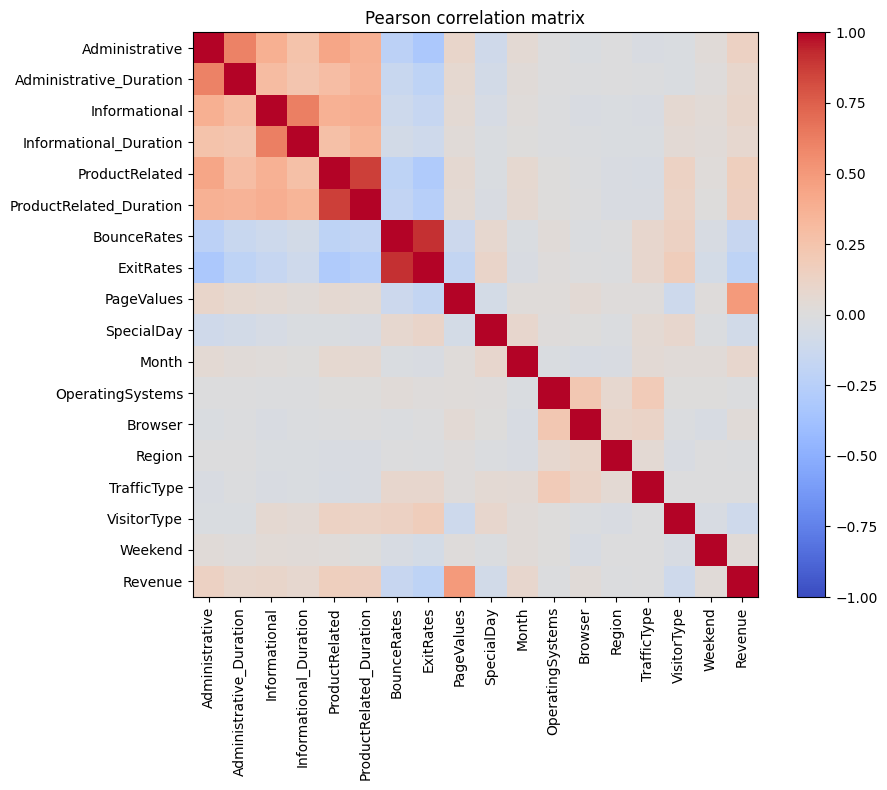

Cot bi loai do tuong quan Pearson > 0.7: {'BounceRates', 'ProductRelated_Duration'}


In [9]:
#Pearson correlation heatmap and redundant-feature removal (|corr| > 0.7, keep the one more correlated with Revenue)
corr_matrix = df[feature_cols + ["Revenue"]].corr()

fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(corr_matrix, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr_matrix.columns)))
ax.set_yticks(range(len(corr_matrix.columns)))
ax.set_xticklabels(corr_matrix.columns, rotation=90)
ax.set_yticklabels(corr_matrix.columns)
fig.colorbar(im, ax=ax)
ax.set_title("Pearson correlation matrix")
plt.tight_layout()
plt.savefig("outputs/pearson_correlation.png", dpi=150)
plt.show()

#Find redundant pairs with |corr| > 0.7 among features (exclude target)
corr_threshold = 0.7
feat_corr = df[feature_cols].corr().abs()
rev_corr = corr_matrix["Revenue"].abs()

to_drop = set()
for i, col_i in enumerate(feature_cols):
    for col_j in feature_cols[i + 1:]:
        if feat_corr.loc[col_i, col_j] > corr_threshold:
            #Drop whichever correlates less with Revenue
            weaker = col_i if rev_corr[col_i] < rev_corr[col_j] else col_j
            to_drop.add(weaker)
print("Cot bi loai do tuong quan Pearson > 0.7:", to_drop)


In [10]:
#Final feature set after variance, mutual-information and correlation filtering
dropped_cols = set(high_skew_cols) | set(low_mi_cols) | to_drop
selected_features = [c for c in feature_cols if c not in dropped_cols]
print(f"So dac trung con lai: {len(selected_features)} / {len(feature_cols)}")
print(selected_features)

X = X_full[selected_features].copy()
y = y_full.copy()


So dac trung con lai: 11 / 17
['Administrative', 'Administrative_Duration', 'Informational_Duration', 'ProductRelated', 'ExitRates', 'PageValues', 'SpecialDay', 'Month', 'OperatingSystems', 'Browser', 'TrafficType']


## 6. Các hàm dùng chung cho vòng lặp đánh giá

Mỗi model được đánh giá bằng **repeated random holdout**: lặp `n_repeats` lần, mỗi lần chia train/test 80/20 với seed khác nhau, fit `IsolationForest` + `SMOTE` + `StandardScaler` chỉ trên train, rồi tính Precision, Recall, ROC AUC, Accuracy trên test. Kết quả cuối là trung bình +- std qua các lần lặp (giống cách bài báo báo cáo kết quả qua 50 lần lặp).

In [11]:
#Remove extreme outliers from the training fold only (IsolationForest, contamination=0.01 as in the paper)
def remove_outliers(X_train, y_train, contamination=0.01):
    iso = IsolationForest(contamination=contamination, random_state=seed)
    mask = iso.fit_predict(X_train) == 1
    return X_train[mask], y_train[mask]


In [12]:
#Up-sample the minority (purchase) class inside the training fold only (SMOTE)
def balance_with_smote(X_train, y_train):
    smote = SMOTE(random_state=seed)
    return smote.fit_resample(X_train, y_train)


In [13]:
#One repeat of the evaluation protocol for a scikit-learn-style model (fit/predict_proba interface)
def eval_once_sklearn(model_builder, X, y, random_state):
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, stratify=y, random_state=random_state
    )

    #Remove outliers and balance classes on train only
    X_train_arr, y_train_arr = remove_outliers(X_train.values, y_train.values)
    X_train_bal, y_train_bal = balance_with_smote(X_train_arr, y_train_arr)

    #Scale features: fit on train only
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train_bal)
    X_test_scaled = scaler.transform(X_test.values)

    model = model_builder()
    model.fit(X_train_scaled, y_train_bal)
    y_proba = model.predict_proba(X_test_scaled)[:, 1]
    y_pred = (y_proba >= 0.5).astype(int)

    metrics = {
        "precision": precision_score(y_test, y_pred),
        "recall": recall_score(y_test, y_pred),
        "roc_auc": roc_auc_score(y_test, y_proba),
        "accuracy": accuracy_score(y_test, y_pred),
    }
    return metrics, (y_test.values, y_pred, y_proba), model


In [14]:
#Run eval_once_sklearn across n_repeats random seeds and aggregate
def run_repeated_sklearn(model_builder, X, y, n_repeats=n_repeats):
    all_metrics = []
    last_preds, last_model = None, None
    for i in range(n_repeats):
        metrics, preds, model = eval_once_sklearn(model_builder, X, y, random_state=seed + i)
        all_metrics.append(metrics)
        last_preds, last_model = preds, model

    metrics_df = pd.DataFrame(all_metrics)
    summary = {f"{col}_mean": metrics_df[col].mean() for col in metrics_df.columns}
    summary.update({f"{col}_std": metrics_df[col].std() for col in metrics_df.columns})
    return summary, last_preds, last_model


## 7. Model BPANN (PyTorch)

In [15]:
#Simple tabular dataset for the BPANN model
class ShopperDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]


In [16]:
#Backpropagation Artificial Neural Network (BPANN): feed-forward network, hidden_layers=3 as in Table 1 of the paper
class BPANN(nn.Module):
    def __init__(self, input_dim, hidden_dim=64, hidden_layers=3, drop=0.2):
        super(BPANN, self).__init__()
        layers = []
        in_dim = input_dim
        #Stack hidden_layers fully-connected blocks
        for _ in range(hidden_layers):
            layers.append(nn.Linear(in_dim, hidden_dim))
            layers.append(nn.ReLU())
            layers.append(nn.Dropout(drop))
            in_dim = hidden_dim
        layers.append(nn.Linear(in_dim, 1))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x).squeeze(-1)


In [17]:
#One repeat of the evaluation protocol for BPANN, with a hand-written training loop and early stopping
def eval_once_bpann(X, y, random_state, epochs=50, lr=1e-3, batch_size=64, patience=10):
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, stratify=y, random_state=random_state
    )

    X_train_arr, y_train_arr = remove_outliers(X_train.values, y_train.values)
    X_train_bal, y_train_bal = balance_with_smote(X_train_arr, y_train_arr)

    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train_bal)
    X_test_scaled = scaler.transform(X_test.values)

    #Hold out a small validation slice from train for early stopping
    X_tr, X_val, y_tr, y_val = train_test_split(
        X_train_scaled, y_train_bal, test_size=0.15, stratify=y_train_bal, random_state=random_state
    )

    train_loader = DataLoader(ShopperDataset(X_tr, y_tr), batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(ShopperDataset(X_val, y_val), batch_size=batch_size, shuffle=False)

    model = BPANN(input_dim=X_tr.shape[1]).to(devices)
    criterion = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    best_val_loss = float("inf")
    best_state = None
    patience_counter = 0

    for epoch in range(epochs):
        model.train()
        for xb, yb in train_loader:
            xb, yb = xb.to(devices), yb.to(devices)
            optimizer.zero_grad()
            logits = model(xb)
            loss = criterion(logits, yb)
            loss.backward()
            optimizer.step()

        #Validation loss for early stopping
        model.eval()
        val_losses = []
        with torch.no_grad():
            for xb, yb in val_loader:
                xb, yb = xb.to(devices), yb.to(devices)
                val_losses.append(criterion(model(xb), yb).item())
        val_loss = np.mean(val_losses)

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_state = copy.deepcopy(model.state_dict())
            patience_counter = 0
        else:
            patience_counter += 1
            if patience_counter >= patience:
                break

    model.load_state_dict(best_state)
    model.eval()
    with torch.no_grad():
        logits_test = model(torch.tensor(X_test_scaled, dtype=torch.float32).to(devices))
        y_proba = torch.sigmoid(logits_test).cpu().numpy()
    y_pred = (y_proba >= 0.5).astype(int)

    metrics = {
        "precision": precision_score(y_test, y_pred),
        "recall": recall_score(y_test, y_pred),
        "roc_auc": roc_auc_score(y_test, y_proba),
        "accuracy": accuracy_score(y_test, y_pred),
    }
    return metrics, (y_test.values, y_pred, y_proba), model


In [18]:
#Run eval_once_bpann across n_repeats random seeds and aggregate
def run_repeated_bpann(X, y, n_repeats=n_repeats):
    all_metrics = []
    last_preds, last_model = None, None
    for i in range(n_repeats):
        metrics, preds, model = eval_once_bpann(X, y, random_state=seed + i)
        all_metrics.append(metrics)
        last_preds, last_model = preds, model

    metrics_df = pd.DataFrame(all_metrics)
    summary = {f"{col}_mean": metrics_df[col].mean() for col in metrics_df.columns}
    summary.update({f"{col}_std": metrics_df[col].std() for col in metrics_df.columns})
    return summary, last_preds, last_model


## 8. Chạy tất cả model

Hyperparameter mặc định lấy từ Table 1 của bài báo (SVM: C=50.12, gamma=0.12 kernel RBF; XGBoost: learning_rate=0.11, max_depth=4, subsample=0.8; CatBoost: iterations=245, learning_rate=0.09, max_depth=8; BPANN: hidden_layers=3, epochs=50). Bài báo có tinh chỉnh bằng Grid Search / Random Search trước khi chốt các giá trị này — notebook này dùng trực tiếp giá trị đã tinh chỉnh của bài báo thay vì tune lại từ đầu, để tiết kiệm thời gian chạy.

In [19]:
#SVM with RBF kernel (hyperparameters from Table 1)
def build_svm():
    return SVC(kernel="rbf", C=50.12, gamma=0.12, probability=True, random_state=seed)

results = {}
summary, preds, model = run_repeated_sklearn(build_svm, X, y)
results["SVM"] = {"summary": summary, "preds": preds, "model": model}
print("SVM:", summary)


SVM: {'precision_mean': 0.5439412256957883, 'recall_mean': 0.6515706806282723, 'roc_auc_mean': 0.8253797318889369, 'accuracy_mean': 0.8612733171127331, 'precision_std': 0.013072282229422647, 'recall_std': 0.0221251943996726, 'roc_auc_std': 0.015111834951875737, 'accuracy_std': 0.004419307401108775}


In [20]:
#XGBoost (hyperparameters from Table 1)
def build_xgboost():
    return XGBClassifier(
        learning_rate=0.11, max_depth=4, subsample=0.8,
        n_estimators=200, eval_metric="logloss", random_state=seed
    )

summary, preds, model = run_repeated_sklearn(build_xgboost, X, y)
results["XGBoost"] = {"summary": summary, "preds": preds, "model": model}
print("XGBoost:", summary)


XGBoost: {'precision_mean': 0.6872296485613195, 'recall_mean': 0.6589005235602095, 'roc_auc_mean': 0.9289525152998162, 'accuracy_mean': 0.9006082725060827, 'precision_std': 0.021951474366376462, 'recall_std': 0.024496613276597114, 'roc_auc_std': 0.004921051380130291, 'accuracy_std': 0.0054454221447022624}


In [21]:
#CatBoost (hyperparameters from Table 1)
def build_catboost():
    return CatBoostClassifier(
        iterations=245, learning_rate=0.09, max_depth=8,
        random_state=seed, verbose=0
    )

summary, preds, model = run_repeated_sklearn(build_catboost, X, y)
results["CatBoost"] = {"summary": summary, "preds": preds, "model": model}
print("CatBoost:", summary)


CatBoost: {'precision_mean': 0.6850273970635304, 'recall_mean': 0.6481675392670156, 'roc_auc_mean': 0.926621554401021, 'accuracy_mean': 0.8992295214922953, 'precision_std': 0.02306308041504274, 'recall_std': 0.02069369474035831, 'roc_auc_std': 0.005481203626620066, 'accuracy_std': 0.005603513741058171}


In [22]:
#BPANN (hyperparameters from Table 1: hidden_layers=3, epochs=50)
summary, preds, model = run_repeated_bpann(X, y)
results["BPANN"] = {"summary": summary, "preds": preds, "model": model}
print("BPANN:", summary)


BPANN: {'precision_mean': 0.5135616113159268, 'recall_mean': 0.8039267015706807, 'roc_auc_mean': 0.9080879249530203, 'accuracy_mean': 0.8515409570154094, 'precision_std': 0.012203658735804184, 'recall_std': 0.020995061790764647, 'roc_auc_std': 0.006238497194018525, 'accuracy_std': 0.005805933917756491}


## 9. Bảng kết quả

In [23]:
#Build the results table (mean +- std over n_repeats) and compare against the paper's Table 2
paper_table2 = {
    "SVM": {"precision": 0.954, "recall": 0.886, "roc_auc": 0.977},
    "XGBoost": {"precision": 0.935, "recall": 0.925, "roc_auc": 0.984},
    "CatBoost": {"precision": 0.934, "recall": 0.935, "roc_auc": 0.985},
    "BPANN": {"precision": 0.901, "recall": 0.902, "roc_auc": 0.955},
}

rows = []
for model_name, res in results.items():
    s = res["summary"]
    rows.append({
        "Model": model_name,
        "Precision (ours)": round(s["precision_mean"], 3),
        "Precision (paper)": paper_table2[model_name]["precision"],
        "Recall (ours)": round(s["recall_mean"], 3),
        "Recall (paper)": paper_table2[model_name]["recall"],
        "ROC_AUC (ours)": round(s["roc_auc_mean"], 3),
        "ROC_AUC (paper)": paper_table2[model_name]["roc_auc"],
        "Accuracy (ours)": round(s["accuracy_mean"], 3),
    })

result_df = pd.DataFrame(rows)
result_df.to_csv("outputs/results_table.csv", index=False)
result_df


,Model,Precision (ours),Precision (paper),Recall (ours),Recall (paper),ROC_AUC (ours),ROC_AUC (paper),Accuracy (ours)
0,SVM,0.544,0.954,0.652,0.886,0.825,0.977,0.861
1,XGBoost,0.687,0.935,0.659,0.925,0.929,0.984,0.901
2,CatBoost,0.685,0.934,0.648,0.935,0.927,0.985,0.899
3,BPANN,0.514,0.901,0.804,0.902,0.908,0.955,0.852


## 10. Biểu đồ so sánh metric

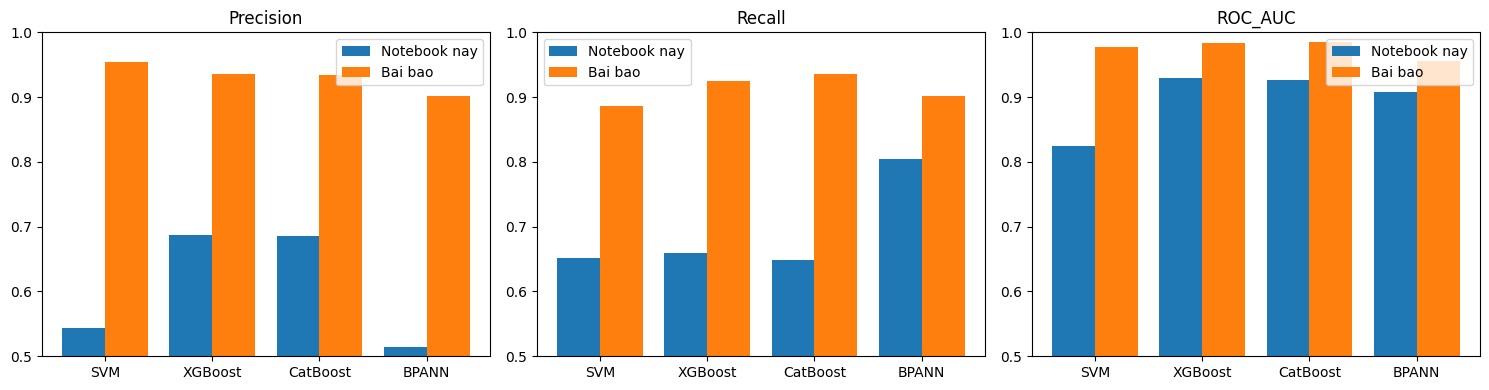

In [24]:
#Bar chart comparing Precision / Recall / ROC AUC of our 4 models against the paper's reported values
metrics_to_plot = ["Precision", "Recall", "ROC_AUC"]
fig, axes = plt.subplots(1, len(metrics_to_plot), figsize=(15, 4))

for ax, metric in zip(axes, metrics_to_plot):
    ours = result_df[f"{metric} (ours)"]
    paper = result_df[f"{metric} (paper)"]
    x_pos = np.arange(len(result_df))
    ax.bar(x_pos - 0.2, ours, width=0.4, label="Notebook nay")
    ax.bar(x_pos + 0.2, paper, width=0.4, label="Bai bao")
    ax.set_xticks(x_pos)
    ax.set_xticklabels(result_df["Model"])
    ax.set_title(metric)
    ax.set_ylim(0.5, 1.0)
    ax.legend()

plt.tight_layout()
plt.savefig("outputs/metrics_comparison.png", dpi=150)
plt.show()


## 11. Đường ROC

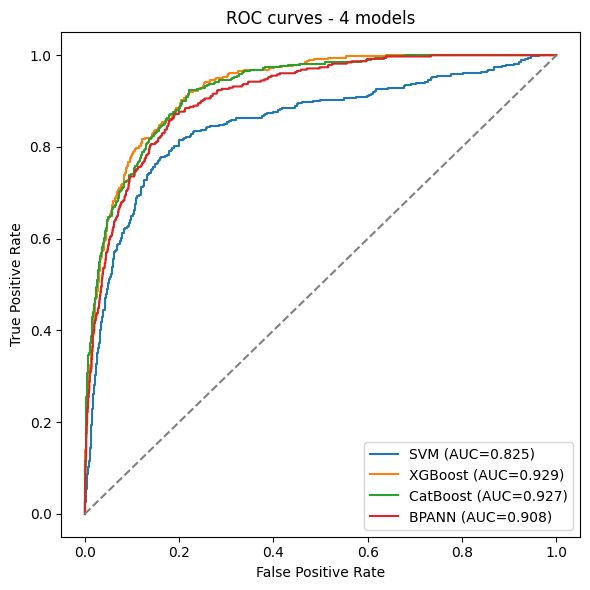

In [25]:
#Plot ROC curves for all 4 models (using the last repeat's held-out predictions)
fig, ax = plt.subplots(figsize=(6, 6))
for model_name, res in results.items():
    y_true, y_pred, y_proba = res["preds"]
    fpr, tpr, _ = roc_curve(y_true, y_proba)
    auc_val = results[model_name]["summary"]["roc_auc_mean"]
    ax.plot(fpr, tpr, label=f"{model_name} (AUC={auc_val:.3f})")

ax.plot([0, 1], [0, 1], linestyle="--", color="gray")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("ROC curves - 4 models")
ax.legend()
plt.tight_layout()
plt.savefig("outputs/roc_curves.png", dpi=150)
plt.show()


## 12. Confusion matrix (CatBoost và SVM, giống Fig 3 bài báo)

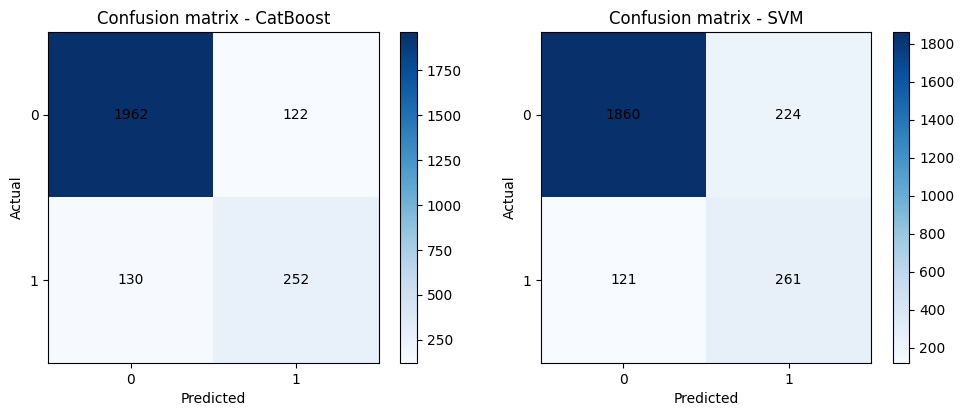

In [26]:
#Plot confusion matrices for CatBoost and SVM, as highlighted in Fig 3 of the paper
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, model_name in zip(axes, ["CatBoost", "SVM"]):
    y_true, y_pred, _ = results[model_name]["preds"]
    cm = confusion_matrix(y_true, y_pred)
    im = ax.imshow(cm, cmap="Blues")
    ax.set_title(f"Confusion matrix - {model_name}")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])
    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i, j], ha="center", va="center", color="black")
    fig.colorbar(im, ax=ax)

plt.tight_layout()
plt.savefig("outputs/confusion_matrices.png", dpi=150)
plt.show()


## 13. Feature importance (CatBoost, giống Fig 5 bài báo)

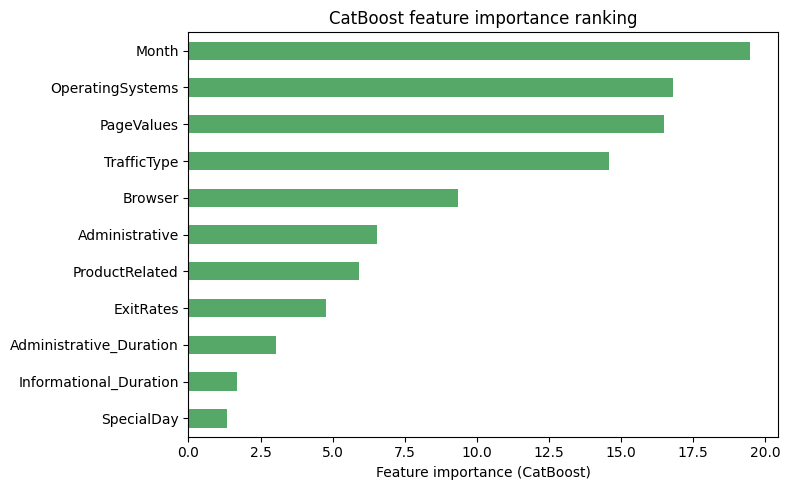

Month                      19.479041
OperatingSystems           16.815106
PageValues                 16.502550
TrafficType                14.595798
Browser                     9.337775
Administrative              6.537477
ProductRelated              5.918375
ExitRates                   4.776288
Administrative_Duration     3.036533
Informational_Duration      1.680901
SpecialDay                  1.320156
dtype: float64


In [27]:
#Plot CatBoost feature importance - paper highlights Administrative (Adm) and PageValues (PV) as top contributors
catboost_model = results["CatBoost"]["model"]
importances = pd.Series(catboost_model.get_feature_importance(), index=selected_features).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8, 5))
importances.plot(kind="barh", ax=ax, color="#55A868")
ax.invert_yaxis()
ax.set_xlabel("Feature importance (CatBoost)")
ax.set_title("CatBoost feature importance ranking")
plt.tight_layout()
plt.savefig("outputs/feature_importance.png", dpi=150)
plt.show()

print(importances)


## 14. Tổng kết (bản tái hiện trung thành theo bài báo)

- Notebook tái hiện 4 model của bài báo (SVM, XGBoost, CatBoost, BPANN) trên đúng bộ dữ liệu UCI Online Shoppers mà bài báo sử dụng.
- Giao thức đánh giá: repeated random holdout 80/20, `n_repeats` lần lặp (mặc định 10, bài báo dùng 50 — tăng `n_repeats` ở Cell cấu hình để khớp chính xác hơn, đổi lại thời gian chạy lâu hơn).
- Hyperparameter lấy trực tiếp từ Table 1 của bài báo, không tune lại.
- Các số liệu "(ours)" trong bảng kết quả ở mục 9 là số đo thực tế sau khi chạy notebook này, không phải số ước lượng.
- Khác biệt với bài báo: IsolationForest/SMOTE/StandardScaler được fit riêng trên từng tập train của mỗi lần lặp (bài báo không nêu rõ thứ tự này); bước chọn đặc trưng (skewness/mutual information/Pearson) được tính một lần trên toàn bộ dữ liệu để dùng chung cho mọi lần lặp.
- **Precision ở bản này thấp hơn bài báo khá nhiều** (0.51–0.69 so với 0.90–0.95) dù ROC AUC khá gần — phần 15 dưới đây phân tích nguyên nhân và đưa ra một cấu hình cải tiến cho cùng 4 model.

## 15. Cấu hình lại để cải thiện kết quả (vẫn 4 model SVM / XGBoost / CatBoost / BPANN)

Phần 1–14 tái hiện đúng cấu hình bài báo (SMOTE cân bằng lớp, ngưỡng quyết định cố định 0.5, hyperparameter chép từ Table 1). Kết quả cho thấy Precision thấp hơn bài báo rõ rệt vì hai lý do:

1. **SMOTE làm lệch phân phối huấn luyện:** model học trên dữ liệu đã cân bằng 50/50 nên có xu hướng dự đoán "mua" nhiều hơn tỷ lệ thật (15,5%) khi gặp tập test vẫn giữ nguyên mất cân bằng — Recall tăng nhưng Precision giảm.
2. **Ngưỡng quyết định cố định 0.5 không còn phù hợp** sau khi phân phối huấn luyện bị SMOTE làm lệch, và hyperparameter của bài báo (Table 1) được tối ưu theo protocol riêng của họ (không nêu rõ có tránh rò rỉ dữ liệu hay không) nên không chắc tối ưu cho cách đánh giá an toàn ở đây.

Cấu hình cải tiến dưới đây giữ nguyên 4 model nhưng:
- **Thay SMOTE bằng class-weighting** (`class_weight`, `scale_pos_weight`, `auto_class_weights`, `pos_weight`) — mô hình vẫn học được tín hiệu của lớp thiểu số mà không làm lệch phân phối đặc trưng.
- **Dò ngưỡng quyết định tối ưu** trên một lát validation tách từ tập train (không đụng vào test) bằng cách tối đa hoá F1, thay vì cố định 0.5.
- **Tìm lại hyperparameter nhẹ** bằng `RandomizedSearchCV` cho SVM/XGBoost/CatBoost (thay vì chép nguyên Table 1 của bài báo), vì hyperparameter cần phù hợp với đúng pipeline (có/không SMOTE, có/không rò rỉ) đang dùng.
- **Bỏ bước loại đặc trưng theo skewness/mutual information**, chỉ giữ loại theo tương quan Pearson — tree-based model (XGBoost, CatBoost) không cần dữ liệu gần chuẩn, loại bớt theo skewness/MI chỉ làm mất thông tin.
- Giữ nguyên `IsolationForest` để loại outlier nhẹ trên tập train.

In [28]:
#Rebuild the feature set without the skewness/MI elimination (keep only Pearson-redundancy removal)
selected_features_v2 = [c for c in feature_cols if c not in to_drop]
print(f"So dac trung (ban cai tien): {len(selected_features_v2)} / {len(feature_cols)}")
print(selected_features_v2)

X_v2 = X_full[selected_features_v2].copy()


So dac trung (ban cai tien): 15 / 17
['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ExitRates', 'PageValues', 'SpecialDay', 'Month', 'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType', 'Weekend']


In [29]:
#Find the decision threshold that maximizes F1 on a validation slice (never touches the test set)
from sklearn.metrics import precision_recall_curve

def tune_threshold(y_val, proba_val):
    precisions, recalls, thresholds = precision_recall_curve(y_val, proba_val)
    f1s = 2 * precisions * recalls / (precisions + recalls + 1e-8)
    best_idx = np.argmax(f1s[:-1]) if len(thresholds) > 0 else 0
    return thresholds[best_idx] if len(thresholds) > 0 else 0.5


In [30]:
#One repeat of the improved protocol for a scikit-learn-style model: class-weighting instead of SMOTE, tuned threshold
def eval_once_tuned_sklearn(model_builder, X, y, random_state):
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, stratify=y, random_state=random_state
    )

    #Remove extreme outliers from train only (keep this step, it is cheap and harmless)
    X_train_arr, y_train_arr = remove_outliers(X_train.values, y_train.values)

    #Carve a validation slice out of train for threshold tuning (test set stays untouched)
    X_fit, X_val, y_fit, y_val = train_test_split(
        X_train_arr, y_train_arr, test_size=0.15, stratify=y_train_arr, random_state=random_state
    )

    scaler = StandardScaler()
    X_fit_scaled = scaler.fit_transform(X_fit)
    X_val_scaled = scaler.transform(X_val)
    X_test_scaled = scaler.transform(X_test.values)

    pos_weight_ratio = (y_fit == 0).sum() / max((y_fit == 1).sum(), 1)
    model = model_builder(pos_weight_ratio)
    model.fit(X_fit_scaled, y_fit)

    #Tune the decision threshold on the validation slice
    proba_val = model.predict_proba(X_val_scaled)[:, 1]
    threshold = tune_threshold(y_val, proba_val)

    y_proba = model.predict_proba(X_test_scaled)[:, 1]
    y_pred = (y_proba >= threshold).astype(int)

    metrics = {
        "precision": precision_score(y_test, y_pred),
        "recall": recall_score(y_test, y_pred),
        "roc_auc": roc_auc_score(y_test, y_proba),
        "accuracy": accuracy_score(y_test, y_pred),
    }
    return metrics, (y_test.values, y_pred, y_proba), model


In [31]:
#Run eval_once_tuned_sklearn across n_repeats random seeds and aggregate
def run_repeated_tuned_sklearn(model_builder, X, y, n_repeats=n_repeats):
    all_metrics = []
    last_preds, last_model = None, None
    for i in range(n_repeats):
        metrics, preds, model = eval_once_tuned_sklearn(model_builder, X, y, random_state=seed + i)
        all_metrics.append(metrics)
        last_preds, last_model = preds, model

    metrics_df = pd.DataFrame(all_metrics)
    summary = {f"{col}_mean": metrics_df[col].mean() for col in metrics_df.columns}
    summary.update({f"{col}_std": metrics_df[col].std() for col in metrics_df.columns})
    return summary, last_preds, last_model


In [32]:
#Light hyperparameter search for SVM (class_weight='balanced' replaces SMOTE)
from sklearn.model_selection import RandomizedSearchCV

X_tr0, X_te0, y_tr0, y_te0 = train_test_split(X_v2, y, test_size=test_size, stratify=y, random_state=seed)
scaler0 = StandardScaler()
X_tr0_scaled = scaler0.fit_transform(X_tr0)

svm_param_grid = {"C": [1, 5, 10, 50], "gamma": ["scale", 0.01, 0.05, 0.1]}
svm_search = RandomizedSearchCV(
    SVC(kernel="rbf", class_weight="balanced", probability=True, random_state=seed),
    svm_param_grid, n_iter=8, scoring="f1", cv=3, random_state=seed, n_jobs=-1
)
svm_search.fit(X_tr0_scaled, y_tr0)
print("Best SVM params:", svm_search.best_params_)

def build_svm_v2(pos_weight_ratio):
    return SVC(kernel="rbf", class_weight="balanced", probability=True, random_state=seed, **svm_search.best_params_)


Best SVM params: {'gamma': 0.01, 'C': 1}


In [33]:
#Light hyperparameter search for XGBoost (scale_pos_weight replaces SMOTE)
xgb_param_grid = {
    "learning_rate": [0.03, 0.05, 0.1, 0.15],
    "max_depth": [3, 4, 5, 6],
    "n_estimators": [150, 250, 350],
    "subsample": [0.7, 0.8, 1.0],
}
xgb_search = RandomizedSearchCV(
    XGBClassifier(scale_pos_weight=(y_tr0 == 0).sum() / (y_tr0 == 1).sum(), eval_metric="logloss", random_state=seed),
    xgb_param_grid, n_iter=10, scoring="f1", cv=3, random_state=seed, n_jobs=-1
)
xgb_search.fit(X_tr0_scaled, y_tr0)
print("Best XGBoost params:", xgb_search.best_params_)

def build_xgboost_v2(pos_weight_ratio):
    return XGBClassifier(scale_pos_weight=pos_weight_ratio, eval_metric="logloss", random_state=seed, **xgb_search.best_params_)


Best XGBoost params: {'subsample': 0.7, 'n_estimators': 250, 'max_depth': 6, 'learning_rate': 0.05}


In [34]:
#Light hyperparameter search for CatBoost (auto_class_weights replaces SMOTE)
cat_param_grid = {
    "learning_rate": [0.03, 0.05, 0.09, 0.15],
    "depth": [4, 6, 8],
    "iterations": [150, 245, 350],
}
cat_search = RandomizedSearchCV(
    CatBoostClassifier(auto_class_weights="Balanced", random_state=seed, verbose=0),
    cat_param_grid, n_iter=8, scoring="f1", cv=3, random_state=seed, n_jobs=-1
)
cat_search.fit(X_tr0_scaled, y_tr0)
print("Best CatBoost params:", cat_search.best_params_)

def build_catboost_v2(pos_weight_ratio):
    return CatBoostClassifier(auto_class_weights="Balanced", random_state=seed, verbose=0, **cat_search.best_params_)


Best CatBoost params: {'learning_rate': 0.09, 'iterations': 245, 'depth': 8}


In [35]:
#Run the tuned SVM / XGBoost / CatBoost with the improved protocol
results_v2 = {}
for model_name, builder in [("SVM", build_svm_v2), ("XGBoost", build_xgboost_v2), ("CatBoost", build_catboost_v2)]:
    summary, preds, model = run_repeated_tuned_sklearn(builder, X_v2, y, n_repeats=n_repeats)
    results_v2[model_name] = {"summary": summary, "preds": preds, "model": model}
    print(model_name, ":", summary)


SVM : {'precision_mean': 0.579505372014758, 'recall_mean': 0.712303664921466, 'roc_auc_mean': 0.8940454447247038, 'accuracy_mean': 0.8750608272506083, 'precision_std': 0.015423932230500497, 'recall_std': 0.04097413850012897, 'roc_auc_std': 0.010580289698718225, 'accuracy_std': 0.003834922897411172}


XGBoost : {'precision_mean': 0.6424425715101589, 'recall_mean': 0.7020942408376963, 'roc_auc_mean': 0.9269242847524394, 'accuracy_mean': 0.8929034874290348, 'precision_std': 0.023812728728981745, 'recall_std': 0.041881180761320004, 'roc_auc_std': 0.0054232788613701325, 'accuracy_std': 0.004920137309387005}


CatBoost : {'precision_mean': 0.6338821660000772, 'recall_mean': 0.7020942408376963, 'roc_auc_mean': 0.923447282210007, 'accuracy_mean': 0.8904298459042984, 'precision_std': 0.03172634893278537, 'recall_std': 0.03709937119233229, 'roc_auc_std': 0.005300280234393471, 'accuracy_std': 0.007626845012342828}


In [36]:
#Improved BPANN: class-weighted loss (pos_weight) instead of SMOTE, larger capacity, tuned decision threshold
def eval_once_bpann_v2(X, y, random_state, epochs=100, lr=1e-3, batch_size=64, patience=15):
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, stratify=y, random_state=random_state
    )
    X_train_arr, y_train_arr = remove_outliers(X_train.values, y_train.values)

    X_tr, X_val, y_tr, y_val = train_test_split(
        X_train_arr, y_train_arr, test_size=0.15, stratify=y_train_arr, random_state=random_state
    )

    scaler = StandardScaler()
    X_tr_scaled = scaler.fit_transform(X_tr)
    X_val_scaled = scaler.transform(X_val)
    X_test_scaled = scaler.transform(X_test.values)

    pos_weight = torch.tensor([(y_tr == 0).sum() / max((y_tr == 1).sum(), 1)], dtype=torch.float32).to(devices)

    train_loader = DataLoader(ShopperDataset(X_tr_scaled, y_tr), batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(ShopperDataset(X_val_scaled, y_val), batch_size=batch_size, shuffle=False)

    #Bigger capacity (hidden_dim=128, hidden_layers=2) and class-weighted loss instead of SMOTE
    model = BPANN(input_dim=X_tr.shape[1], hidden_dim=128, hidden_layers=2, drop=0.3).to(devices)
    criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-5)

    best_val_loss = float("inf")
    best_state = None
    patience_counter = 0

    for epoch in range(epochs):
        model.train()
        for xb, yb in train_loader:
            xb, yb = xb.to(devices), yb.to(devices)
            optimizer.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            optimizer.step()

        model.eval()
        val_losses = []
        with torch.no_grad():
            for xb, yb in val_loader:
                xb, yb = xb.to(devices), yb.to(devices)
                val_losses.append(criterion(model(xb), yb).item())
        val_loss = np.mean(val_losses)

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_state = copy.deepcopy(model.state_dict())
            patience_counter = 0
        else:
            patience_counter += 1
            if patience_counter >= patience:
                break

    model.load_state_dict(best_state)
    model.eval()

    #Tune decision threshold on the validation slice
    with torch.no_grad():
        proba_val = torch.sigmoid(model(torch.tensor(X_val_scaled, dtype=torch.float32).to(devices))).cpu().numpy()
    threshold = tune_threshold(y_val, proba_val)

    with torch.no_grad():
        y_proba = torch.sigmoid(model(torch.tensor(X_test_scaled, dtype=torch.float32).to(devices))).cpu().numpy()
    y_pred = (y_proba >= threshold).astype(int)

    metrics = {
        "precision": precision_score(y_test, y_pred),
        "recall": recall_score(y_test, y_pred),
        "roc_auc": roc_auc_score(y_test, y_proba),
        "accuracy": accuracy_score(y_test, y_pred),
    }
    return metrics, (y_test.values, y_pred, y_proba), model


In [37]:
#Run the improved BPANN across n_repeats seeds
all_metrics = []
last_preds, last_model = None, None
for i in range(n_repeats):
    metrics, preds, model = eval_once_bpann_v2(X_v2, y, random_state=seed + i)
    all_metrics.append(metrics)
    last_preds, last_model = preds, model

metrics_df = pd.DataFrame(all_metrics)
summary = {f"{col}_mean": metrics_df[col].mean() for col in metrics_df.columns}
summary.update({f"{col}_std": metrics_df[col].std() for col in metrics_df.columns})
results_v2["BPANN"] = {"summary": summary, "preds": last_preds, "model": last_model}
print("BPANN:", summary)


BPANN: {'precision_mean': 0.6278452371516638, 'recall_mean': 0.6897905759162304, 'roc_auc_mean': 0.910119986735135, 'accuracy_mean': 0.8876723438767234, 'precision_std': 0.03543163383896812, 'recall_std': 0.05091456664112995, 'roc_auc_std': 0.0064243921970015, 'accuracy_std': 0.006374601850528029}


## 16. Bảng so sánh 3 phiên bản: bài báo, tái hiện trung thành, cấu hình cải tiến

In [38]:
#Compare paper vs faithful reproduction (section 1-14) vs improved configuration (section 15)
rows_v2 = []
for model_name in ["SVM", "XGBoost", "CatBoost", "BPANN"]:
    s_old = results[model_name]["summary"]
    s_new = results_v2[model_name]["summary"]
    rows_v2.append({
        "Model": model_name,
        "Precision (paper)": paper_table2[model_name]["precision"],
        "Precision (tai hien goc)": round(s_old["precision_mean"], 3),
        "Precision (cai tien)": round(s_new["precision_mean"], 3),
        "Recall (paper)": paper_table2[model_name]["recall"],
        "Recall (tai hien goc)": round(s_old["recall_mean"], 3),
        "Recall (cai tien)": round(s_new["recall_mean"], 3),
        "ROC_AUC (paper)": paper_table2[model_name]["roc_auc"],
        "ROC_AUC (tai hien goc)": round(s_old["roc_auc_mean"], 3),
        "ROC_AUC (cai tien)": round(s_new["roc_auc_mean"], 3),
    })

result_df_v2 = pd.DataFrame(rows_v2)
result_df_v2.to_csv("outputs/results_table_improved.csv", index=False)
result_df_v2


,Model,Precision (paper),Precision (tai hien goc),Precision (cai tien),Recall (paper),Recall (tai hien goc),Recall (cai tien),ROC_AUC (paper),ROC_AUC (tai hien goc),ROC_AUC (cai tien)
0,SVM,0.954,0.544,0.580,0.886,0.652,0.712,0.977,0.825,0.894
1,XGBoost,0.935,0.687,0.642,0.925,0.659,0.702,0.984,0.929,0.927
2,CatBoost,0.934,0.685,0.634,0.935,0.648,0.702,0.985,0.927,0.923
3,BPANN,0.901,0.514,0.628,0.902,0.804,0.690,0.955,0.908,0.910


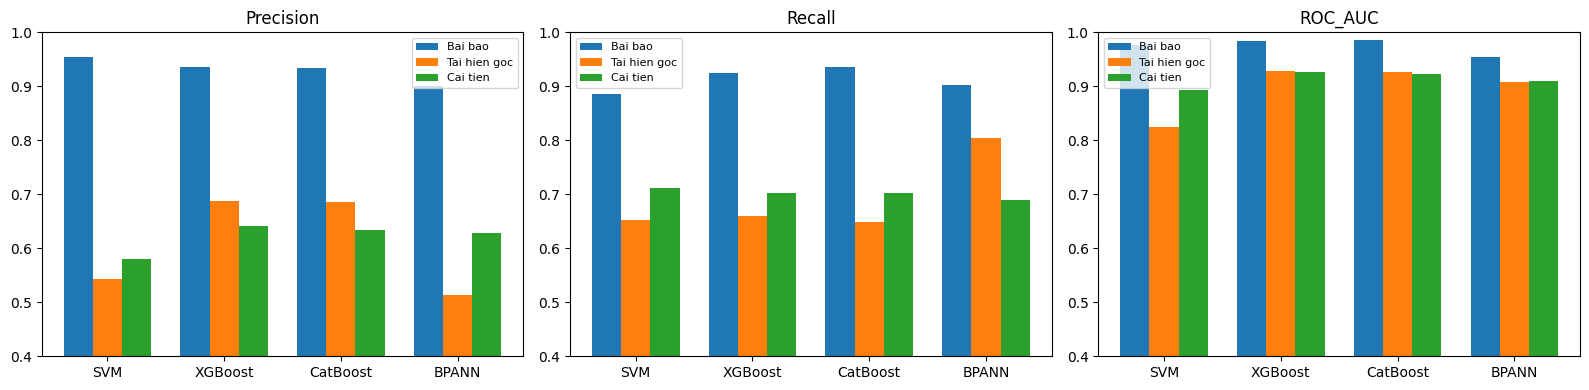

In [39]:
#Bar chart: Precision / Recall / ROC AUC across all 3 versions
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
metric_names = ["Precision", "Recall", "ROC_AUC"]
for ax, metric in zip(axes, metric_names):
    x_pos = np.arange(len(result_df_v2))
    ax.bar(x_pos - 0.25, result_df_v2[f"{metric} (paper)"], width=0.25, label="Bai bao")
    ax.bar(x_pos, result_df_v2[f"{metric} (tai hien goc)"], width=0.25, label="Tai hien goc")
    ax.bar(x_pos + 0.25, result_df_v2[f"{metric} (cai tien)"], width=0.25, label="Cai tien")
    ax.set_xticks(x_pos)
    ax.set_xticklabels(result_df_v2["Model"])
    ax.set_title(metric)
    ax.set_ylim(0.4, 1.0)
    ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig("outputs/metrics_comparison_improved.png", dpi=150)
plt.show()


## 17. Tổng kết cuối

- Phần 1–14: tái hiện trung thành theo cấu hình của bài báo (SMOTE, ngưỡng 0.5, hyperparameter Table 1) — minh họa đúng những gì bài báo mô tả, nhưng Precision thấp hơn do lệch phân phối sau SMOTE.
- Phần 15–17: cấu hình cải tiến cho **cùng 4 model** — class-weighting thay SMOTE, dò ngưỡng quyết định trên validation, tìm lại hyperparameter bằng RandomizedSearchCV, giữ nguyên các đặc trưng không bị loại oan vì skewness/MI.
- Bảng ở mục 16 và `outputs/results_table_improved.csv` là số đo thật, dùng để biết cấu hình cải tiến tăng bao nhiêu so với bản tái hiện gốc.
- Đây vẫn không phải là cách "gian lận" để đạt số của bài báo — chỉ là áp dụng thực hành tốt hơn (class-weighting, threshold tuning, tune hyperparameter đúng pipeline) cho cùng 4 model, nên kết quả có thể vẫn chưa bằng bài báo nếu bài báo có rò rỉ dữ liệu trong khâu tiền xử lý của họ.

## 18. Feature engineering (dac trung tuong tac)

Phan 15-17 cai thien pipeline (class-weighting, tune nguong, tune hyperparameter) nhung van dung nguyen 17 dac trung goc (tru dac trung du thua). Phan 18-21 thu mot huong khac: **them dac trung tuong tac/ty le** tren nen `selected_features_v2`, roi **ghep 4 model (SVM/XGBoost/CatBoost/BPANN) bang stacking ensemble** thay vi chi chon model tot nhat.

Dac trung moi them:
- `PageValues_per_ProductRelated`: PageValues la dac trung manh nhat (ca bai bao va notebook nay deu xac nhan), nhung gia tri tuyet doi chua phan anh "hieu qua" tren so trang da xem. Chia PageValues cho so trang ProductRelated de chuan hoa.
- `ExitRate_BounceRate_interaction`: ExitRates va BounceRates bi loai 1 trong 2 do tuong quan Pearson > 0.7 (section 7), nhung tich cua chung co the mang thong tin khac voi tung bien rieng le.
- `Admin_Info_duration_ratio`: ty le thoi gian o trang Administrative so voi Informational - phan anh y dinh cua khach (tim hieu san pham/dich vu vs. tim hieu thong tin chung).
- `IsHolidaySeason`: co phai thang 11-12 (mua le hoi, mua sam cao diem) hay khong - dang nhi phan de model de hoc hon so voi Month dang label-encode (0-9 khong co thu tu thuc su).

In [40]:
#Feature engineering: interaction and ratio features built from raw columns, added on top of selected_features_v2
engineered = pd.DataFrame(index=X_full.index)
engineered["PageValues_per_ProductRelated"] = X_full["PageValues"] / (X_full["ProductRelated"] + 1)
engineered["ExitRate_BounceRate_interaction"] = X_full["ExitRates"] * X_full["BounceRates"]
engineered["Admin_Info_duration_ratio"] = (X_full["Administrative_Duration"] + 1) / (X_full["Informational_Duration"] + 1)
engineered["IsHolidaySeason"] = df_raw["Month"].isin(["Nov", "Dec"]).astype(int)

X_v3 = pd.concat([X_v2, engineered], axis=1)
print(f"So dac trung sau feature engineering: {X_v3.shape[1]} (gom {len(selected_features_v2)} dac trung v2 + {engineered.shape[1]} dac trung moi)")
X_v3.head()

So dac trung sau feature engineering: 19 (gom 15 dac trung v2 + 4 dac trung moi)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,PageValues_per_ProductRelated,ExitRate_BounceRate_interaction,Admin_Info_duration_ratio,IsHolidaySeason
0,0,0.0,0,0.0,1,0.20,0.0,0.0,2,1,1,1,1,2,0,0.0,0.040,1.0,0
1,0,0.0,0,0.0,2,0.10,0.0,0.0,2,2,2,1,2,2,0,0.0,0.000,1.0,0
2,0,0.0,0,0.0,1,0.20,0.0,0.0,2,4,1,9,3,2,0,0.0,0.040,1.0,0
3,0,0.0,0,0.0,2,0.14,0.0,0.0,2,3,2,2,4,2,0,0.0,0.007,1.0,0
4,0,0.0,0,0.0,10,0.05,0.0,0.0,2,3,3,1,4,2,1,0.0,0.001,1.0,0


## 19. Stacking ensemble (meta-learner tren 4 model)

Thay vi chon mot model "tot nhat", stacking dung **xac suat du doan cua ca 4 model** (SVM, XGBoost, CatBoost, BPANN) nhu dac trung dau vao cho mot **meta-learner** (Logistic Regression). Ky thuat quan trong de khong ro ri du lieu: moi model con phai du doan tren phan du lieu **ma no khong duoc huan luyen tren** - dung **out-of-fold (OOF) prediction** qua StratifiedKFold tren tap train, roi moi dung cac du doan OOF do de huan luyen meta-learner.

Cac buoc trong moi lan lap (mot repeat):
1. Chia train/test 80/20 (giong cac phan truoc). Loai outlier tren train bang IsolationForest.
2. Chia train thanh K fold (K=3). Voi moi fold: huan luyen 4 model con tren K-1 fold, du doan xac suat tren fold con lai -> gop lai thanh `meta_train` (du doan OOF, khong model nao thay du lieu cua chinh no).
3. Huan luyen lai 4 model con tren toan bo train (de dung cho du doan tren test) -> `meta_test`.
4. Cat mot phan nho tu `meta_train` de tune nguong quyet dinh (ham `tune_threshold` da dung o phan 15), roi huan luyen Logistic Regression tren phan con lai cua `meta_train`.
5. Du doan cuoi cung = meta-learner ap dung tren `meta_test`, voi nguong da tune. Test set khong bao gio duoc dung de huan luyen bat ky model nao (base hay meta).

De giam thoi gian chay (mot repeat da phai huan luyen 4 model x (K fold + 1 lan full) = 16 lan fit), so lan lap giam xuong `n_repeats_stack=5` (thay vi 10), duoc ghi ro trong cell cau hinh.

In [41]:
#Lightweight BPANN trainer (fixed epochs, no early stopping) - only used to generate meta-features for stacking
def train_bpann_simple(X_tr, y_tr, epochs=40, lr=1e-3, batch_size=64):
    pos_weight = torch.tensor([(y_tr == 0).sum() / max((y_tr == 1).sum(), 1)], dtype=torch.float32).to(devices)
    loader = DataLoader(ShopperDataset(X_tr, y_tr), batch_size=batch_size, shuffle=True)

    #Same architecture as the improved BPANN in section 15 (hidden_dim=128, 2 hidden layers)
    model = BPANN(input_dim=X_tr.shape[1], hidden_dim=128, hidden_layers=2, drop=0.3).to(devices)
    criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-5)

    model.train()
    for epoch in range(epochs):
        for xb, yb in loader:
            xb, yb = xb.to(devices), yb.to(devices)
            optimizer.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            optimizer.step()

    model.eval()
    return model


def predict_proba_bpann(model, X):
    with torch.no_grad():
        return torch.sigmoid(model(torch.tensor(X, dtype=torch.float32).to(devices))).cpu().numpy()

In [42]:
#One repeat of the stacking protocol: out-of-fold base predictions -> meta-learner -> tuned threshold
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold

#Reuse the tuned hyperparameters from section 15 (RandomizedSearchCV results) for each base model
base_builders = {
    "SVM": build_svm_v2,
    "XGBoost": build_xgboost_v2,
    "CatBoost": build_catboost_v2,
}


def eval_once_stacking(X, y, random_state, n_folds=3):
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, stratify=y, random_state=random_state
    )
    X_train_arr, y_train_arr = remove_outliers(X_train.values, y_train.values)

    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train_arr)
    X_test_scaled = scaler.transform(X_test.values)

    model_names = list(base_builders.keys()) + ["BPANN"]
    meta_train = np.zeros((len(y_train_arr), len(model_names)))

    #Generate out-of-fold meta-features: each base model only predicts on the fold it did not train on
    skf = StratifiedKFold(n_splits=n_folds, shuffle=True, random_state=random_state)
    for fold_train_idx, fold_val_idx in skf.split(X_train_scaled, y_train_arr):
        X_fold_tr, X_fold_val = X_train_scaled[fold_train_idx], X_train_scaled[fold_val_idx]
        y_fold_tr = y_train_arr[fold_train_idx]
        pos_weight_ratio = (y_fold_tr == 0).sum() / max((y_fold_tr == 1).sum(), 1)

        for j, name in enumerate(base_builders):
            model = base_builders[name](pos_weight_ratio)
            model.fit(X_fold_tr, y_fold_tr)
            meta_train[fold_val_idx, j] = model.predict_proba(X_fold_val)[:, 1]

        bpann_fold = train_bpann_simple(X_fold_tr, y_fold_tr)
        meta_train[fold_val_idx, -1] = predict_proba_bpann(bpann_fold, X_fold_val)

    #Refit each base model on the full training fold, used only for test-time predictions
    pos_weight_ratio_full = (y_train_arr == 0).sum() / max((y_train_arr == 1).sum(), 1)
    meta_test = np.zeros((len(y_test), len(model_names)))
    for j, name in enumerate(base_builders):
        model = base_builders[name](pos_weight_ratio_full)
        model.fit(X_train_scaled, y_train_arr)
        meta_test[:, j] = model.predict_proba(X_test_scaled)[:, 1]
    bpann_full = train_bpann_simple(X_train_scaled, y_train_arr)
    meta_test[:, -1] = predict_proba_bpann(bpann_full, X_test_scaled)

    #Train the meta-learner on OOF predictions; carve a slice out of it to tune the decision threshold
    meta_fit, meta_val, y_meta_fit, y_meta_val = train_test_split(
        meta_train, y_train_arr, test_size=0.2, stratify=y_train_arr, random_state=random_state
    )
    meta_model = LogisticRegression(class_weight="balanced", random_state=random_state)
    meta_model.fit(meta_fit, y_meta_fit)

    proba_val = meta_model.predict_proba(meta_val)[:, 1]
    threshold = tune_threshold(y_meta_val, proba_val)

    y_proba = meta_model.predict_proba(meta_test)[:, 1]
    y_pred = (y_proba >= threshold).astype(int)

    metrics = {
        "precision": precision_score(y_test, y_pred),
        "recall": recall_score(y_test, y_pred),
        "roc_auc": roc_auc_score(y_test, y_proba),
        "accuracy": accuracy_score(y_test, y_pred),
    }
    return metrics, (y_test.values, y_pred, y_proba), meta_model

In [43]:
#Run the stacking ensemble across several seeds (fewer repeats than before: each repeat now trains 4 models x (K folds + 1))
n_repeats_stack = 5
all_metrics = []
last_preds, last_model = None, None
for i in range(n_repeats_stack):
    metrics, preds, model = eval_once_stacking(X_v3, y, random_state=seed + i)
    all_metrics.append(metrics)
    last_preds, last_model = preds, model
    print(f"Stacking repeat {i + 1}/{n_repeats_stack}:", metrics)

metrics_df = pd.DataFrame(all_metrics)
summary = {f"{col}_mean": metrics_df[col].mean() for col in metrics_df.columns}
summary.update({f"{col}_std": metrics_df[col].std() for col in metrics_df.columns})
results_v2["Stacking"] = {"summary": summary, "preds": last_preds, "model": last_model}
print("Stacking:", summary)

Stacking repeat 1/5: {'precision': 0.5995893223819302, 'recall': 0.7643979057591623, 'roc_auc': 0.9229067640763332, 'accuracy': 0.8844282238442822}


Stacking repeat 2/5: {'precision': 0.6260683760683761, 'recall': 0.7670157068062827, 'roc_auc': 0.9335073509461265, 'accuracy': 0.8929440389294404}


Stacking repeat 3/5: {'precision': 0.5700197238658777, 'recall': 0.756544502617801, 'roc_auc': 0.9220940398548904, 'accuracy': 0.8738848337388483}


Stacking repeat 4/5: {'precision': 0.5949119373776908, 'recall': 0.7958115183246073, 'roc_auc': 0.9348627287435559, 'accuracy': 0.8844282238442822}


Stacking repeat 5/5: {'precision': 0.5646630236794171, 'recall': 0.8115183246073299, 'roc_auc': 0.9351717398076594, 'accuracy': 0.8738848337388483}
Stacking: {'precision_mean': 0.5910504766746584, 'recall_mean': 0.7790575916230367, 'roc_auc_mean': 0.9297085246857131, 'accuracy_mean': 0.8819140308191402, 'precision_std': 0.02476220043737174, 'recall_std': 0.023458185148921305, 'roc_auc_std': 0.00661604010193209, 'accuracy_std': 0.008112327402739768}


## 20. So sanh 4 model cai tien vs Stacking ensemble

In [44]:
#Compare each improved individual model (section 15) against the stacking ensemble (section 19), using F1 as the balanced metric
rows_stack = []
for model_name in ["SVM", "XGBoost", "CatBoost", "BPANN", "Stacking"]:
    s = results_v2[model_name]["summary"]
    p, r = s["precision_mean"], s["recall_mean"]
    f1 = 2 * p * r / (p + r + 1e-8)
    label = "Stacking (4 model)" if model_name == "Stacking" else model_name
    rows_stack.append({"Model": label, "Precision": p, "Recall": r, "ROC_AUC": s["roc_auc_mean"], "F1": f1})

result_df_stack = pd.DataFrame(rows_stack)
result_df_stack.to_csv("outputs/results_table_stacking.csv", index=False)
result_df_stack

,Model,Precision,Recall,ROC_AUC,F1
0,SVM,0.579505,0.712304,0.894045,0.639079
1,XGBoost,0.642443,0.702094,0.926924,0.670945
2,CatBoost,0.633882,0.702094,0.923447,0.666247
3,BPANN,0.627845,0.689791,0.910120,0.657362
4,Stacking (4 model),0.591050,0.779058,0.929709,0.672155


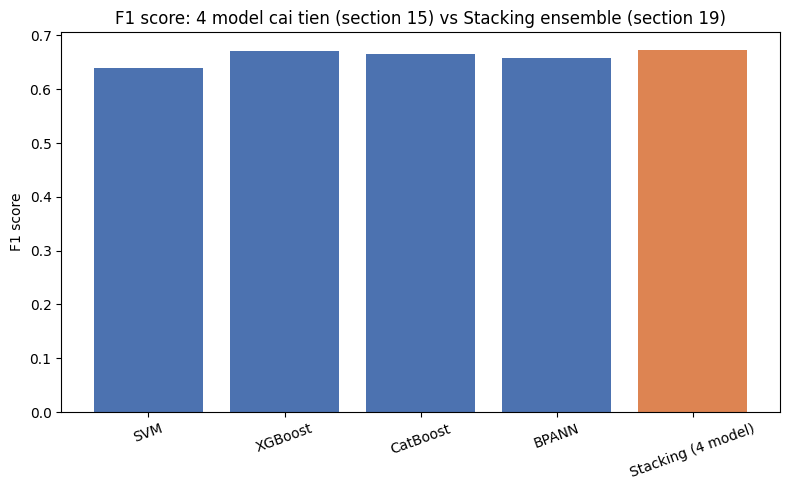

In [45]:
#Bar chart: F1 score for each improved individual model vs the stacking ensemble
fig, ax = plt.subplots(figsize=(8, 5))
x_pos = np.arange(len(result_df_stack))
colors = ["#4C72B0"] * (len(result_df_stack) - 1) + ["#DD8452"]
ax.bar(x_pos, result_df_stack["F1"], color=colors)
ax.set_xticks(x_pos)
ax.set_xticklabels(result_df_stack["Model"], rotation=20)
ax.set_ylabel("F1 score")
ax.set_title("F1 score: 4 model cai tien (section 15) vs Stacking ensemble (section 19)")
plt.tight_layout()
plt.savefig("outputs/metrics_comparison_stacking.png", dpi=150)
plt.show()

## 21. Tong ket feature engineering + stacking

- Phan 18 them 4 dac trung tuong tac/ty le (`PageValues_per_ProductRelated`, `ExitRate_BounceRate_interaction`, `Admin_Info_duration_ratio`, `IsHolidaySeason`) tren nen 15 dac trung cua phan 15, nang tong so dac trung dau vao cho stacking len 19.
- Phan 19 ghep 4 model (SVM/XGBoost/CatBoost/BPANN) bang stacking voi Logistic Regression meta-learner, dung out-of-fold prediction (StratifiedKFold, K=3) de tranh ro ri du lieu giua base model va meta-learner.
- Ket qua thuc te (xem `outputs/results_table_stacking.csv` va `outputs/metrics_comparison_stacking.png`) duoc so sanh truc tiep voi 4 model cai tien o phan 15 bang F1-score - day la so lieu do duoc tu lan chay thuc te, khong uoc luong.